[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sampriti-sr/MLP_Course/blob/kshitij-variant/docs/timeseries/08-holidays-regime-change.ipynb)

# Holidays, Outside Drivers and Regime Change

<div class="admonition info">
<p class="admonition-title">What you will be able to do after this page</p>
<ul>
<li>Make a forecaster calendar-aware by masking holidays and forecasting them from earlier holidays.</li>
<li>Decide whether an outside driver is legal at the forecast origin.</li>
<li>Quantify how different windows fail and recover after a regime change.</li>
<li>Build and calibrate a simple error-monitoring alarm.</li>
</ul>
</div>

**Prerequisites:** Pages 1 to 7 of this track. **Dataset:** NYC Taxi (Jan to Mar 2023; Jan to May 2020). **Time:** about 40 minutes.

In [1]:
try:
    import mlp_data
except ImportError:  # e.g. a fresh Colab runtime
    %pip install -q "mlp-course @ git+https://github.com/sampriti-sr/MLP_Course@kshitij-variant"
    import mlp_data

import time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mlp_data import forecasting as fc, style
from mlp_data.timeseries import taxi_hourly

style.apply()
pd.set_option("display.width", 120)
pd.set_option("display.float_format", "{:,.2f}".format)

## The situation

Every model in this track so far shares one hidden assumption: **tomorrow behaves like the recent past**. This page is about the two ways that assumption fails.

1. **Known unusual days**: holidays are on the calendar months ahead, yet the best forecaster on the backtesting page was blind to them.
2. **Unknown breaks**: a change in the world that nothing in the history foreshadows. We use the starkest real example in the data: New York taxi demand in spring 2020.

For the first we can fix the forecaster. For the second we cannot predict the break; what we can do is notice it quickly and limit the damage.

In [2]:
from pandas.tseries.holiday import USFederalHolidayCalendar

y = taxi_hourly(["2023-01", "2023-02", "2023-03"]).asfreq("h").interpolate()
H = 24
origins = fc.rolling_origins(y.index, first_origin="2023-02-12")           # the 48 origins from the backtesting page
scale_history = y[:"2023-02-11"]
holidays = set(USFederalHolidayCalendar().holidays("2023-01-01", "2023-03-31").date)
print("US federal holidays in the period:", sorted(str(d) for d in holidays))

US federal holidays in the period: ['2023-01-02', '2023-01-16', '2023-02-20']


## 1. Holidays

The federal calendar gives three dates in our three months: **2 January** (New Year's Day, observed on the Monday), **16 January** (Martin Luther King Day) and **20 February** (Presidents' Day). All three are Mondays, and all three disturb the four-week average in two ways, which we can see in the earlier per-origin errors:

- on the holiday itself, the forecast is for an ordinary Monday and the day is much quieter;
- for weeks **afterwards**, the holiday sits inside the "last four weeks" window and drags the average down for the same weekday. The weekly copy that failed on 27 February did it for exactly this reason.

Two fixes, each using only what is known at the origin (a calendar is not leakage, as long as the dates are known in advance):

1. **Mask holidays out of the history**, so an ordinary day is averaged over ordinary days only (`holiday_aware_mean(..., holiday_profile=False)`).
2. **Forecast a holiday from earlier holidays**: for a target on a holiday, average the same hour of the earlier holidays in the history.

`fc.holiday_aware_mean` implements both.

In [3]:
forecasters = {
    "4-week average (blind to holidays)": lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=4),
    "+ holidays masked out of the history": lambda hist, idx: fc.holiday_aware_mean(hist, idx, holidays, holiday_profile=False),
    "+ holiday forecast from earlier holidays": lambda hist, idx: fc.holiday_aware_mean(hist, idx, holidays),
}
runs = {name: fc.backtest(y, f, origins=origins, horizon=H) for name, f in forecasters.items()}
table = pd.DataFrame({name: fc.score(bt, scale_history) for name, bt in runs.items()}).T
table.style.format({"MAE": "{:,.0f}", "RMSE": "{:,.0f}", "sMAPE": "{:.1%}", "MASE": "{:.2f}"})

,MAE,RMSE,sMAPE,MASE
4-week average (blind to holidays),281,406,7.7%,0.77
+ holidays masked out of the history,273,398,7.4%,0.74
+ holiday forecast from earlier holidays,266,382,7.0%,0.73


Each step helps, and the second matters more for the *hardest* days (the RMSE falls from about 406 to about 382, because the worst day was a holiday). Which days changed, and by how much?

In [4]:
per_origin = pd.DataFrame({name: (bt["actual"] - bt["forecast"]).abs().groupby(bt["origin"]).mean() for name, bt in runs.items()})
per_origin.columns = ["blind", "masked", "masked + holiday profile"]
changed = per_origin[(per_origin["blind"] - per_origin["masked + holiday profile"]).abs() > 40]
changed.assign(weekday=changed.index.day_name()).round(0)

,blind,masked,masked + holiday profile,weekday
origin,,,,
2023-02-13,307.00,230.00,230.00,Monday
2023-02-20,594.00,594.00,276.00,Monday
2023-02-27,309.00,165.00,165.00,Monday
2023-03-06,224.00,161.00,161.00,Monday
2023-03-13,469.00,353.00,353.00,Monday


The gains sit on **five days**: **20 February** itself (594 → 276) and four later **Mondays whose four-week window contained a holiday** (13 February, 27 February, 6 March and 13 March). Masking repairs those four; the holiday profile repairs the holiday itself. On the other 43 origins the three versions give identical forecasts.

Is the gain real or luck? The same paired comparison as the backtesting page:

In [5]:
d = per_origin["masked + holiday profile"] - per_origin["blind"]
print(f"mean difference {d.mean():+.1f} pickups/hour, standard error {d.std() / np.sqrt(len(d)):.1f}, better on {(d < 0).sum()} of {len(d)} days")

mean difference -15.2 pickups/hour, standard error 7.7, better on 6 of 48 days


About −15 ± 8 pickups an hour: roughly two standard errors, with the forecast better on 6 days and identical on the other 42 (it was never worse). That is a *plausible* improvement, but notice what it rests on: **one holiday in the test period, and a holiday profile learned from just two earlier holidays**. Treat the 20 February result as an illustration, not proof; over a full year, with eleven federal holidays and the many other unusual days (Christmas Eve, big parades, snowstorms), a holiday feature in a model with real training data is the right tool. The principle is what carries over: **give the forecaster the calendar, and keep unusual days out of the averages used for ordinary ones.**

## 2. Outside drivers: what may you feed the model?

Holidays are the simplest *exogenous* variable: known long in advance. Other outside drivers (weather, promotions, events, prices) can lift a forecast a lot, but each raises the same question as every feature in this track: **would this value be available at the origin?**

| Driver | At forecast time you have | Legal input | The trap |
|---|---|---|---|
| Calendar (holiday, weekday, school term) | the schedule | yes | none: the date is the date |
| Planned events, promotions, price changes | the plan | yes | plans change; use the plan *as it stood at the origin* |
| Weather | a *weather forecast* | the **forecast**, as issued at the origin | training on observed weather and predicting with a forecast gives a model that has never seen forecast error |
| Competitor behaviour, news | nothing | no | cannot be known in advance |
| The target's own recent values | lags at least the horizon (page 5) | yes | lags shorter than the horizon leak |

The weather row deserves emphasis. The tempting setup is to merge *observed* temperature with the demand history, train, backtest, and celebrate. In production the model receives a weather *forecast*, which is wrong in ways the model never learned. The honest backtest uses the forecast that existed at each origin, or, if archived forecasts are not available, adds noise to the observed values to mimic forecast error. This course does not add a weather dataset: the datasets it uses are audited for licence and stability (`data/README.md`), and a weather source with archived forecasts is an open item there.

## 3. Regime change: New York, spring 2020

Now the break nobody could forecast. We use five months of 2020: January and February, then March to May. (This page downloads these extra monthly files once, about 240 MB in total; they are cached afterwards.) Daily totals first.

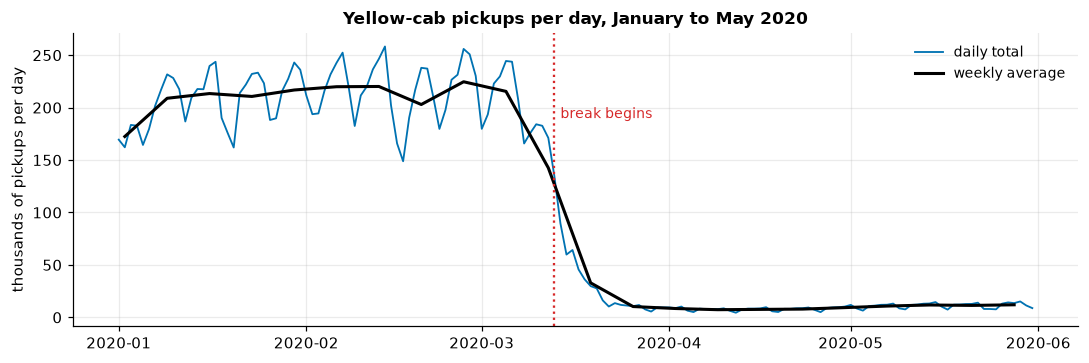

average day in February: 216,911 pickups;  average day in 6 to 26 April: 7,599  (96% lower)


In [6]:
h2020 = taxi_hourly(["2020-01", "2020-02", "2020-03", "2020-04", "2020-05"])
daily = h2020.resample("D").sum()
daily.index.freq = "D"
weekly = daily.resample("W").mean()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(daily.index, daily / 1000, lw=1.2, label="daily total")
ax.plot(weekly.index - pd.Timedelta(days=3), weekly / 1000, "k", lw=2, label="weekly average")
ax.axvline(pd.Timestamp("2020-03-13"), color="tab:red", ls=":"); ax.text(pd.Timestamp("2020-03-14"), 190, "break begins", color="tab:red", fontsize=9)
ax.set(ylabel="thousands of pickups per day", title="Yellow-cab pickups per day, January to May 2020"); ax.legend(loc="upper right")
plt.tight_layout(); plt.show()
february = daily["2020-02-03":"2020-03-01"].mean()
april = daily["2020-04-06":"2020-04-26"].mean()
print(f"average day in February: {february:,.0f} pickups;  average day in 6 to 26 April: {april:,.0f}  ({1 - april / february:.0%} lower)")

Demand fell by about **96%** within weeks. No amount of history from January and February contained any information about this. Three forecasters for the next 7 days, from every origin between 1 February and 25 May:

- **same weekday last week**: long-memory-free, adapts after one week;
- **4-week average**: smoother in normal times, but it keeps averaging the old regime for four weeks;
- **weekday shape × latest 7-day level**: keeps the day-of-week *pattern* from the last four weeks but takes the *level* from the most recent week.

In [7]:
def shape_times_level(hist, idx, weeks=4):
    recent = hist.iloc[-7 * weeks:]
    ratio = recent / recent.rolling(7, center=True, min_periods=4).mean()      # each day relative to its own week
    shape = ratio.groupby(recent.index.dayofweek).mean()
    level = hist.iloc[-7:].mean()                                              # the most recent week only
    return pd.Series([shape[t.dayofweek] * level for t in idx], index=idx)

origins_2020 = fc.rolling_origins(daily.index, first_origin="2020-02-01", last_origin="2020-05-25")
shock = {
    "same weekday last week": lambda hist, idx: fc.seasonal_naive(hist, idx, 7),
    "4-week average": lambda hist, idx: fc.seasonal_mean(hist, idx, weeks=4),
    "weekday shape x latest 7-day level": shape_times_level,
}
runs_2020 = {name: fc.backtest(daily, f, origins=origins_2020, horizon=7) for name, f in shock.items()}
ape = {name: ((bt["actual"] - bt["forecast"]).abs() / bt["actual"]).groupby(bt["time"]).mean() for name, bt in runs_2020.items()}

periods = {"calm: 1 Feb to 8 Mar": ("2020-02-01", "2020-03-08"), "break: 13 Mar to 12 Apr": ("2020-03-13", "2020-04-12"),
           "new normal: from 20 Apr": ("2020-04-20", "2020-05-31")}
summary = pd.DataFrame({name: {label: s[a:b].mean() for label, (a, b) in periods.items()} for name, s in ape.items()}).T
summary.style.format("{:.0%}")

,calm: 1 Feb to 8 Mar,break: 13 Mar to 12 Apr,new normal: from 20 Apr
same weekday last week,7%,152%,11%
4-week average,5%,862%,18%
weekday shape x latest 7-day level,6%,166%,11%


This table is **percentage error** (appropriate here because the level changes by a factor of 25; absolute errors would be dominated by the pre-break days).

- **Calm weeks**: the 4-week average is best (about 5% error), the weekly copy worst (about 7%). Averaging reduces noise.
- **During the break** every forecaster fails, but by very different amounts. The four-week average **over-forecasts by almost nine times on average** (a 860% error), because for four weeks it keeps averaging in the old, busy weeks. The weekly copy and the level-adjusted forecaster are wrong by about 150% to 170%, a fifth as badly.
- **In the new normal** the average has not recovered (about 18% error, still blending in the collapse) while the other two are back near 11% to 12%.

This is the classic **adaptivity versus noise** trade-off: a long window is better when the world is stable and much worse when it changes. The week-by-week picture shows how long each takes to recover:

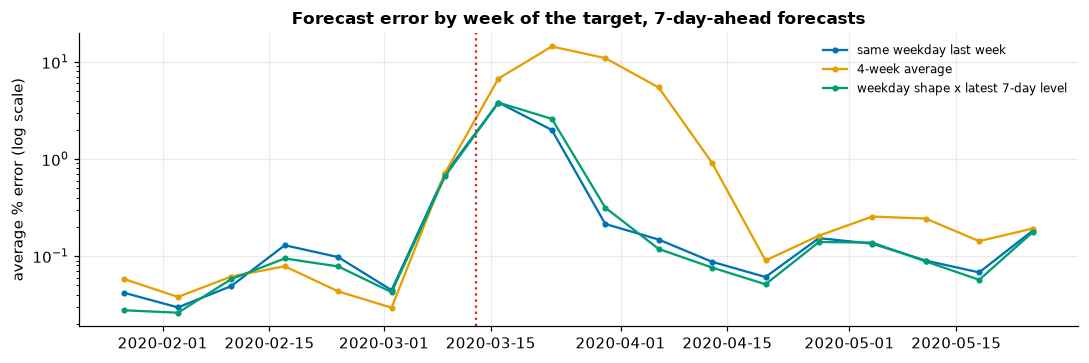

weeks with an error above 100%: {'same weekday last week': 2, '4-week average': 4, 'weekday shape x latest 7-day level': 2}


In [8]:
weekly_ape = pd.DataFrame({name: s.groupby(s.index.to_period("W")).mean() for name, s in ape.items()})
weekly_ape.index = weekly_ape.index.start_time

fig, ax = plt.subplots(figsize=(10, 3.4))
for name in weekly_ape:
    ax.plot(weekly_ape.index, weekly_ape[name], marker="o", ms=3, lw=1.5, label=name)
ax.set_yscale("log")
ax.axvline(pd.Timestamp("2020-03-13"), color="tab:red", ls=":")
ax.set(ylabel="average % error (log scale)", title="Forecast error by week of the target, 7-day-ahead forecasts"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("weeks with an error above 100%:", {name: int((weekly_ape[name] > 1).sum()) for name in weekly_ape})

On the log scale the pre-break errors sit near 5% and every curve leaps by roughly two orders of magnitude (100 to 350 times). The weekly copy and the level-adjusted forecaster behave almost identically, and are back below 35% error by the week of 30 March, within about two weeks of their worst week; the four-week average is still at 91% in the week of 13 April, six weeks after the break began. **No forecaster saw it coming; they differ in how long they stay wrong.**

## 4. Noticing the break

Since nobody can predict a break, the practical defence is **monitoring**: compare forecasts with actuals as they arrive and raise an alarm when the recent error is far outside its normal range. The rule below uses the four-week average's one-day-ahead percentage error, smoothed over three days, with a threshold set from a *calm baseline period* (1 February to 8 March) as twice the largest value seen there.

In [9]:
one_day = runs_2020["4-week average"].query("step == 1").set_index("time")
daily_error = (one_day["actual"] - one_day["forecast"]).abs() / one_day["actual"]
smoothed = daily_error.rolling(3).mean()

baseline = smoothed["2020-02-01":"2020-03-08"]
threshold = 2 * baseline.max()
alarms = smoothed[smoothed > threshold]
print(f"calm-period error: typical {baseline.median():.1%}, largest {baseline.max():.1%}  ->  alarm threshold {threshold:.0%}")
print("first alarm:", alarms.index[0].date(), f"(smoothed error {alarms.iloc[0]:.0%})")
smoothed["2020-03-09":"2020-03-16"].map("{:.0%}".format).to_frame("3-day smoothed error").T

calm-period error: typical 4.5%, largest 17.5%  ->  alarm threshold 35%
first alarm: 2020-03-13 (smoothed error 51%)


time,2020-03-09,2020-03-10,2020-03-11,2020-03-12,2020-03-13,2020-03-14,2020-03-15,2020-03-16
3-day smoothed error,6%,10%,16%,29%,51%,88%,136%,168%


The alarm fires on **13 March**, the first day the collapse is large, and not before. It is *not* fooled by Presidents' Day (17 February 2020), which lies inside the baseline period: that holiday produces the largest calm-period error (the baseline maximum of about 17.5%), and the threshold is set above it. A threshold chosen from a period with no holiday would have fired a false alarm in February.

Two honest limits. First, the alarm fires *after* the first bad forecasts: monitoring shortens the damage, it cannot remove it. Second, it only says "the error is abnormal", not why. A holiday, a data outage and a pandemic all look the same to it. The response is a human one: investigate, then choose among **widening the intervals**, **falling back to a more adaptive forecaster**, **retraining on the new regime only**, or **switching the forecast off** until the world is understood.

<div class="admonition tip">
<p class="admonition-title">A pre-agreed plan beats improvisation</p>
<p>Decide before the alarm what happens when it fires: who is told, which fallback forecaster takes over (here a weekly copy or the level-adjusted one), and how a human signs off the return to the normal model. The lifecycle track's monitoring page covers the same loop for classifiers.</p>
</div>

## Pitfalls at a glance

| Surprise | Cause | Fix |
|---|---|---|
| Forecast is poor for weeks after a holiday | the holiday sits in the averaging window | mask known unusual days out of the history |
| Holiday forecast is wrong although the calendar is in the model | too few holidays in the training data | pool holidays, or share the holiday effect with a larger data set; be honest about the sample size |
| A model trained with observed weather fails in production | production uses a forecast of the weather | train and test with the forecast available at each origin |
| Long-window model breaks for weeks after a shift | the old regime keeps being averaged in | shorter windows, level adjustment, or retraining triggers |
| Alarm fires on every holiday | threshold set from a period without any | build the baseline from a period with ordinary unusual days |
| Same alarm for a pandemic and for a data outage | an error monitor says *that*, not *why* | add data-quality checks and human review |

## Check yourself

<details class="question">
<summary>1. A colleague says a calendar feature is leakage because it uses information about the future. What is the answer?</summary>

Leakage is information that **would not exist at the forecast origin**. The date of a public holiday is fixed far in advance, so it is available. A *forecast of the weather* is available; the *observed* weather of the target day is not. The test is always whether the value, as it will be known at the origin, is what the model sees.

</details>

<details class="question">
<summary>2. Why did masking holidays from the history improve forecasts for ordinary Mondays weeks after the holiday?</summary>

Because the holiday value was entering the four-week average for the same weekday and hour, pulling the forecast below the level of an ordinary Monday for the next four weeks. Removing it from the average means ordinary days are forecast from ordinary days. The fix is cheap and the effect is local: it matters only for the days whose averaging window contained a holiday.

</details>

<details class="question">
<summary>3. The weekly copy and the level-adjusted forecaster recovered about six weeks sooner than the four-week average in 2020. Why might you still not use them in normal operation?</summary>

In calm weeks they were **less accurate** than the four-week average (about 6% to 7% error against 5%): using only the most recent week adds noise. You pay for adaptivity every day to insure against a break that may never come. The sensible design is a stable forecaster in normal times plus a monitor that switches to an adaptive one when the alarm fires.

</details>

## Exercises

<details class="question">
<summary>Apply only the masking step (no holiday profile) and compare with the full version. Which part of the gain does masking explain?</summary>

```python
masked = fc.score(runs["+ holidays masked out of the history"], scale_history)["MAE"]
full = fc.score(runs["+ holiday forecast from earlier holidays"], scale_history)["MAE"]
blind = fc.score(runs["4-week average (blind to holidays)"], scale_history)["MAE"]
print(blind, masked, full)
```

The MAE goes from about 281 (blind) to about 273 (masked) to about 266 (masked plus holiday profile): masking explains about half of the total gain in MAE, the holiday profile the rest. In RMSE the holiday profile matters most, since the worst day of the period was the holiday.

</details>

<details class="question">
<summary>Change the alarm threshold to 1.5 times the baseline maximum and to 3 times. When does the first alarm fire in each case, and what does it tell you?</summary>

```python
for factor in (1.5, 2, 3):
    print(factor, smoothed[smoothed > factor * baseline.max()].index[0].date())
```

The first alarm fires on **12 March** with 1.5 times, **13 March** with 2 times and **14 March** with 3 times: each step up in the threshold costs about a day of delay, because the smoothed error roughly doubles every day at the start of the break (16%, 29%, 51%, 88%). Only a threshold *below* the baseline maximum would have fired in February (a false alarm), which is why the baseline must include an ordinary holiday. The choice of multiplier moves detection by a day or two here because the shock is huge; for a subtle drift it matters far more.

</details>

<details class="question">
<summary>Repeat the 2020 comparison using the average of the last 2 weeks instead of 4. Where does it sit between the weekly copy and the 4-week average?</summary>

```python
runs_2020["2-week average"] = fc.backtest(daily, lambda h, i: fc.seasonal_mean(h, i, weeks=2), origins=origins_2020, horizon=7)
```

It lands in between on every period: about 6% in calm weeks (4-week: 5%, weekly copy: 7%), about 350% during the break (862% and 152%) and about 13% in the new normal (18% and 12%). The window length is a dial between noise and adaptivity: no setting is best in both regimes.

</details>

## Recap

- A forecaster assumes tomorrow looks like the recent past. **Holidays** break that on a known date; give the model the calendar, and keep unusual days out of the averages for ordinary ones.
- A holiday feature learned from two holidays is fragile; the gain here (about −15 ± 8 pickups an hour) is plausible, not proven.
- **Outside drivers** are legal only as they will be known at the origin: use weather *forecasts*, not observed weather.
- A **regime change** (here, a 96% fall in demand) cannot be forecast. Long windows fail longest; level-adjusted forecasts recover fastest but cost accuracy in calm times.
- **Monitor** forecast error with a threshold built from a calm period that includes ordinary unusual days; plan the response in advance.

**Next:** *the recommender-systems track, or the exercises and projects section*.